# Gênero e negação de crédito imobiliário nos EUA (HMDA 2025)

SME0828 - Introdução à Ciência de Dados

Professor: Francisco A. Rodrigues

Alunos:

Aluno 1, Nº USP

Aluno 2, Nº USP

Aluno 3, Nº USP

## 1. Introdução

Nos Estados Unidos, a lei HMDA (*Home Mortgage Disclosure Act*) obriga as instituições financeiras a informar cada pedido de financiamento imobiliário que recebem. Os dados são publicados todo ano pelo FFIEC e trazem, para cada pedido, a decisão do banco (aprovado ou negado), características do solicitante (renda, idade, sexo, raça), do empréstimo (valor, tipo, comprometimento da renda) e do imóvel. Usamos a base de 2025, com 13,5 milhões de pedidos.

A pergunta do trabalho é se mulheres têm o crédito negado com mais frequência que homens, e se essa diferença continua quando comparamos pessoas com o mesmo perfil de risco. Como bancos usam cada vez mais modelos automáticos para decidir, também perguntamos o que acontece quando treinamos um modelo de classificação com essas decisões.

Hipóteses:

- H1: depois de controlar renda, comprometimento da renda (DTI), parcela financiada do imóvel (LTV), tipo de empréstimo, banco e estado, o gênero ainda está associado à negação.
- H2: um modelo que prevê a negação **sem** usar a variável gênero continua negando mais um dos grupos, porque outras variáveis carregam informação sobre o gênero.
- H3: entre os empréstimos aprovados, o preço do crédito é diferente para mulheres e homens.

O HMDA público não informa se o empréstimo foi pago. Por isso, os modelos aqui aprendem a reproduzir a decisão dos bancos e não o risco real de inadimplência. O protocolo com as hipóteses e os filtros está em `docs/protocolo.md`, e cada etapa tem um notebook próprio com mais detalhes (`01` a `08`).

## 2. Bibliotecas

In [1]:
from pathlib import Path
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyfixest as pf
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, accuracy_score,
                             f1_score, roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir())
os.chdir(ROOT)
os.makedirs("figuras", exist_ok=True)

SEMENTE = 444
random.seed(SEMENTE)
np.random.seed(SEMENTE)

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#898781"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

## 3. Dados e construção da amostra

A base completa (gerada pelo notebook `01_dados`) tem pedidos de todo tipo: refinanciamentos, imóveis para investimento, pedidos feitos por casais, pedidos que o cliente abandonou. Para comparar homens e mulheres em situações parecidas, ficamos com um tipo de pedido bem definido: uma pessoa sozinha pedindo financiamento para comprar o imóvel onde vai morar, com decisão final do banco.

Como a base não cabe inteira na memória, lemos primeiro só as colunas usadas nos filtros.

In [2]:
ARQUIVO = "data/hmda_2025.parquet"

colunas_filtro = ["action_taken", "loan_purpose", "occupancy_type", "total_units", "lien_status",
                  "business_or_commercial_purpose", "open_end_line_of_credit", "reverse_mortgage",
                  "co_applicant_sex", "derived_sex"]
data = pd.read_parquet(ARQUIVO, columns=colunas_filtro)
print("Número de linhas e colunas:", data.shape)

Número de linhas e colunas: (13543606, 10)


Os códigos seguem o dicionário de dados do HMDA. Aplicamos os filtros em sequência e guardamos quantos pedidos sobram depois de cada um.

In [3]:
fluxo = [("Base completa", len(data))]

data = data[data["action_taken"].isin(["1", "3"])]
fluxo.append(("Aprovado ou negado", len(data)))
data = data[data["loan_purpose"] == "1"]
fluxo.append(("Compra de imóvel", len(data)))
data = data[data["occupancy_type"] == "1"]
fluxo.append(("Residência principal", len(data)))
data = data[data["total_units"].isin(["1", "2", "3", "4"])]
fluxo.append(("1 a 4 unidades", len(data)))
data = data[data["lien_status"] == "1"]
fluxo.append(("Primeira hipoteca", len(data)))
data = data[data["business_or_commercial_purpose"] == "2"]
fluxo.append(("Sem finalidade comercial", len(data)))
data = data[data["open_end_line_of_credit"] == "2"]
fluxo.append(("Sem crédito rotativo", len(data)))
data = data[data["reverse_mortgage"] == "2"]
fluxo.append(("Sem hipoteca reversa", len(data)))
data = data[data["co_applicant_sex"] == "5"]
fluxo.append(("Sem co-candidato", len(data)))
data = data[data["derived_sex"].isin(["Male", "Female"])]
fluxo.append(("Sexo informado", len(data)))

fluxograma = pd.DataFrame(fluxo, columns=["Etapa", "Pedidos"])
fluxograma["Removidos"] = -fluxograma["Pedidos"].diff().fillna(0).astype(int)
fluxograma

,Etapa,Pedidos,Removidos
0,Base completa,13543606,0
1,Aprovado ou negado,8942981,4600625
2,Compra de imóvel,4199851,4743130
3,Residência principal,3689287,510564
4,1 a 4 unidades,3689186,101
5,Primeira hipoteca,3518731,170455
6,Sem finalidade comercial,3435124,83607
7,Sem crédito rotativo,3409972,25152
8,Sem hipoteca reversa,3409746,226
9,Sem co-candidato,1850476,1559270


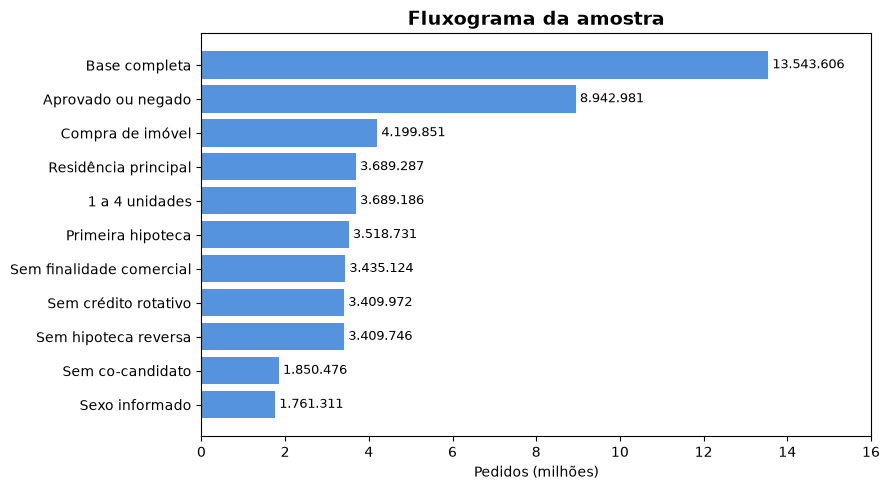

In [4]:
plt.figure(figsize=(9, 5))
plt.barh(fluxograma["Etapa"], fluxograma["Pedidos"] / 1e6, color=AZUL, alpha=0.8)
for i, n in enumerate(fluxograma["Pedidos"]):
    plt.text(n / 1e6 + 0.1, i, f"{n:,}".replace(",", "."), va="center", fontsize=9)
plt.gca().invert_yaxis()
plt.xlim(0, 16)
plt.xlabel("Pedidos (milhões)")
plt.title("Fluxograma da amostra", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_fluxograma.png", dpi=150)
plt.show()

Dos 13,5 milhões de pedidos, ficamos com 1.761.311, cerca de 13% da base. Os maiores cortes foram os pedidos sem decisão final do banco (4,6 milhões), os que não eram para compra de imóvel (4,7 milhões) e os feitos junto com um co-candidato (1,6 milhão). Alguns filtros removeram poucos pedidos, como o de 1 a 4 unidades (101), porque os filtros anteriores já tinham tirado quase todos esses casos.

Agora lemos as colunas que vamos analisar, já com os mesmos filtros aplicados na leitura.

In [5]:
colunas = ["lei", "state_code", "action_taken", "derived_sex", "income", "debt_to_income_ratio",
           "combined_loan_to_value_ratio", "loan_amount", "loan_type", "applicant_age",
           "derived_race", "derived_ethnicity", "interest_rate", "rate_spread", "total_loan_costs"]
filtros = [("action_taken", "in", ["1", "3"]), ("loan_purpose", "==", "1"), ("occupancy_type", "==", "1"),
           ("total_units", "in", ["1", "2", "3", "4"]), ("lien_status", "==", "1"),
           ("business_or_commercial_purpose", "==", "2"), ("open_end_line_of_credit", "==", "2"),
           ("reverse_mortgage", "==", "2"), ("co_applicant_sex", "==", "5"),
           ("derived_sex", "in", ["Male", "Female"])]

data = pd.read_parquet(ARQUIVO, columns=colunas, filters=filtros)
data["negado"] = (data["action_taken"] == "3").astype(int)
data["mulher"] = (data["derived_sex"] == "Female").astype(int)
data = data.drop(["action_taken", "derived_sex"], axis=1)

print("Número de linhas e colunas:", data.shape)
data.head()

Número de linhas e colunas: (1761311, 15)


,lei,state_code,income,debt_to_income_ratio,combined_loan_to_value_ratio,loan_amount,loan_type,applicant_age,derived_race,derived_ethnicity,interest_rate,rate_spread,total_loan_costs,negado,mulher
0,549300QFJDBOCX7WKY08,TX,65,44,97,305000,1,25-34,White,Hispanic or Latino,5.375,-0.676,7234.4,0,0
1,549300HW662MN1WU8550,CA,178,42,80,665000,1,35-44,White,Not Hispanic or Latino,6.625,0.169,7728.95,0,1
2,549300HW662MN1WU8550,CA,61,50%-60%,96.5,255000,2,<25,American Indian or Alaska Native,Hispanic or Latino,5.875,0.750,15920.84,0,0
3,549300HW662MN1WU8550,MN,69,20%-<30%,97,145000,1,25-34,White,Not Hispanic or Latino,6.499,0.414,7826.8,0,1
4,549300D36J5CQX0I4F44,MI,59,20%-<30%,98.189,175000,2,<25,White,Not Hispanic or Latino,5.990,0.648,4541.31,0,0


### 3.1 Valores faltantes

No HMDA, a falta de informação aparece como texto: `NA`, `Exempt` (bancos pequenos são dispensados de informar alguns campos) e `8888` (idade não informada). Trocamos esses códigos por `NaN` e convertemos as colunas numéricas.

O DTI vem misturado: em faixas (`<20%`, `20%-<30%` etc.) e, entre 36% e 49%, como número exato. Juntamos os valores exatos na faixa `36%-<50%`.

In [6]:
data = data.replace(["NA", "Exempt", "8888", ""], np.nan)

numericas = ["income", "combined_loan_to_value_ratio", "loan_amount", "interest_rate", "rate_spread", "total_loan_costs"]
data[numericas] = data[numericas].astype(float)

ordem_dti = ["<20%", "20%-<30%", "30%-<36%", "36%-<50%", "50%-60%", ">60%"]
faixas = {f: f for f in ordem_dti}
for v in range(36, 50):
    faixas[str(v)] = "36%-<50%"
data["dti"] = pd.Categorical(data["debt_to_income_ratio"].map(faixas), categories=ordem_dti, ordered=True)
data = data.drop("debt_to_income_ratio", axis=1)

data.isnull().sum().sort_values(ascending=False)

total_loan_costs                344086
rate_spread                     302188
interest_rate                   290685
combined_loan_to_value_ratio    192754
dti                              24451
state_code                       17039
income                           13289
applicant_age                      274
loan_type                            0
lei                                  0
loan_amount                          0
derived_race                         0
derived_ethnicity                    0
negado                               0
mulher                               0
dtype: int64

Taxa de juros e custos não existem para pedidos negados, então esses faltantes são esperados. As variáveis que importam para a comparação são renda, DTI e LTV. Vamos ver se elas faltam mais em algum grupo.

In [7]:
chave = ["income", "dti", "combined_loan_to_value_ratio"]
falta = data[chave].isnull()
tabela_faltantes = 100 * pd.DataFrame({
    "Aprovados": falta[data["negado"] == 0].mean(),
    "Negados": falta[data["negado"] == 1].mean(),
    "Homens": falta[data["mulher"] == 0].mean(),
    "Mulheres": falta[data["mulher"] == 1].mean(),
})
tabela_faltantes.index = ["Renda", "DTI", "LTV"]
tabela_faltantes.round(1)

,Aprovados,Negados,Homens,Mulheres
Renda,0.7,1.0,0.7,0.9
DTI,0.9,3.9,1.3,1.6
LTV,5.4,39.2,10.2,12.1


Os faltantes não estão distribuídos ao acaso. O LTV falta em 39,2% dos pedidos negados e em 5,4% dos aprovados. Uma explicação provável é que, quando o pedido é recusado cedo, o banco nem chega a avaliar o imóvel. Entre homens e mulheres a diferença é pequena (10,2% contra 12,1%).

Na base principal usamos só os casos completos. Isso tira mais pedidos negados do que aprovados, e a taxa de negação cai de 16,5% para 11,1%. Por isso, no notebook `08_robustez`, repetimos a regressão da H1 numa base com os faltantes preenchidos pela mediana, e a conclusão não mudou.

In [8]:
principal = data.dropna(subset=chave).reset_index(drop=True)
print("Antes:", data.shape, f"- negados: {data['negado'].mean():.1%}")
print("Depois:", principal.shape, f"- negados: {principal['negado'].mean():.1%}")

Antes: (1761311, 15) - negados: 16.5%
Depois: (1547246, 15) - negados: 11.1%


## 4. Análise descritiva

Começamos pela comparação direta: a proporção de pedidos negados entre homens e mulheres, com intervalo de confiança de 95% (aproximação normal para proporções).

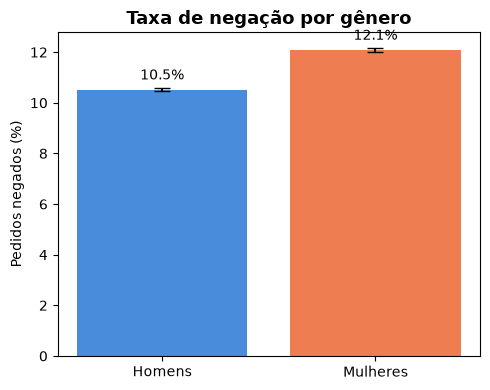

Diferença: 1.57 pontos percentuais


,count,mean,ic
Homens,944301,0.1052,0.0006
Mulheres,602945,0.1209,0.0008


In [9]:
resumo = principal.groupby("mulher")["negado"].agg(["count", "mean"])
resumo.index = ["Homens", "Mulheres"]
resumo["ic"] = 1.96 * np.sqrt(resumo["mean"] * (1 - resumo["mean"]) / resumo["count"])

plt.figure(figsize=(5, 4))
plt.bar(resumo.index, 100 * resumo["mean"], yerr=100 * resumo["ic"], color=[AZUL, LARANJA], alpha=0.85, capsize=6)
for i, v in enumerate(resumo["mean"]):
    plt.text(i, 100 * v + 0.4, f"{100 * v:.1f}%", ha="center")
plt.ylabel("Pedidos negados (%)")
plt.title("Taxa de negação por gênero", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_negacao_genero.png", dpi=150)
plt.show()

print(f"Diferença: {100 * (resumo.loc['Mulheres', 'mean'] - resumo.loc['Homens', 'mean']):.2f} pontos percentuais")
resumo.round(4)

Será que homens e mulheres da amostra têm perfis de risco parecidos? Comparamos as principais variáveis.

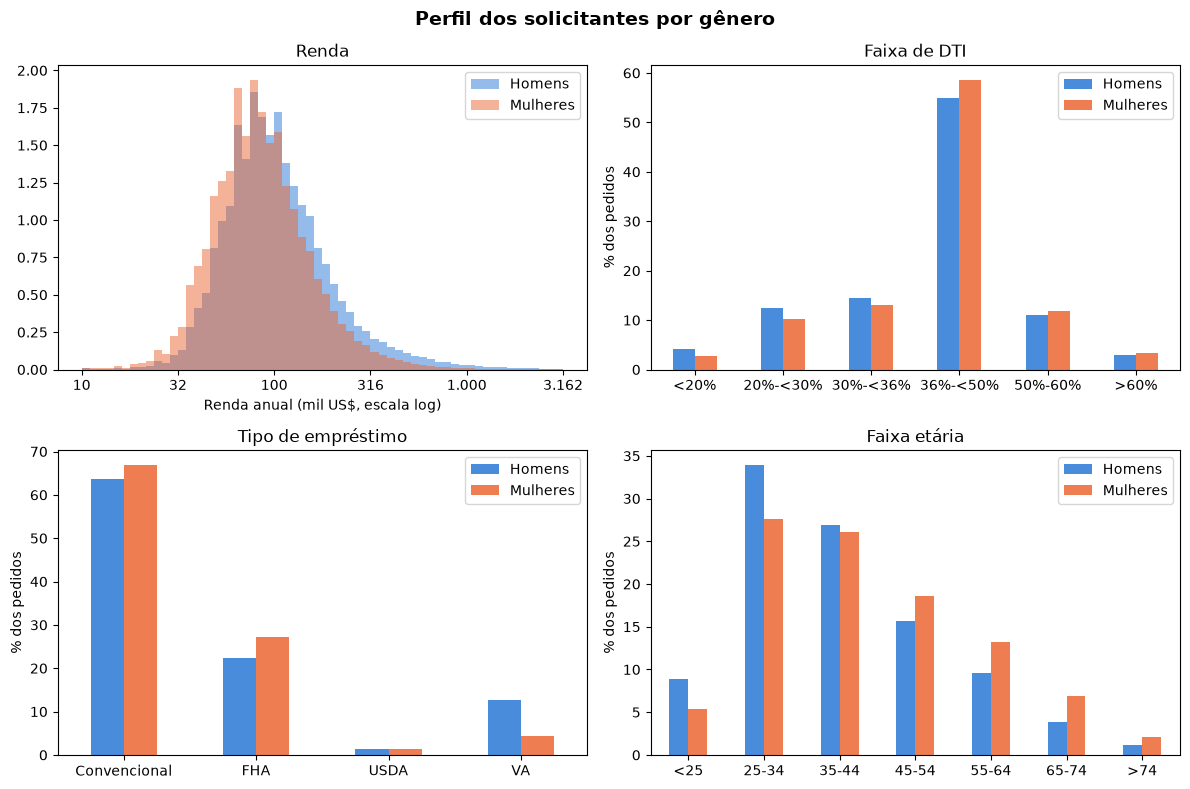

Renda mediana (mil US$): {0: 95.0, 1: 81.0}


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for valor, cor, nome in [(0, AZUL, "Homens"), (1, LARANJA, "Mulheres")]:
    renda = principal.loc[(principal["mulher"] == valor) & (principal["income"] > 0), "income"]
    axes[0, 0].hist(np.log10(renda), bins=60, range=(1, 3.5), density=True, alpha=0.5, color=cor, label=nome)
axes[0, 0].set_xticks([1, 1.5, 2, 2.5, 3, 3.5], ["10", "32", "100", "316", "1.000", "3.162"])
axes[0, 0].set_xlabel("Renda anual (mil US$, escala log)")
axes[0, 0].set_title("Renda")
axes[0, 0].legend()

dti_genero = 100 * pd.crosstab(principal["dti"], principal["mulher"], normalize="columns")
dti_genero.columns = ["Homens", "Mulheres"]
dti_genero.plot(kind="bar", ax=axes[0, 1], color=[AZUL, LARANJA], alpha=0.85, rot=0)
axes[0, 1].set_ylabel("% dos pedidos")
axes[0, 1].set_xlabel("")
axes[0, 1].set_title("Faixa de DTI")

tipos = {"1": "Convencional", "2": "FHA", "3": "VA", "4": "USDA"}
tipo_genero = 100 * pd.crosstab(principal["loan_type"].map(tipos), principal["mulher"], normalize="columns")
tipo_genero.columns = ["Homens", "Mulheres"]
tipo_genero.plot(kind="bar", ax=axes[1, 0], color=[AZUL, LARANJA], alpha=0.85, rot=0)
axes[1, 0].set_ylabel("% dos pedidos")
axes[1, 0].set_xlabel("")
axes[1, 0].set_title("Tipo de empréstimo")

ordem_idade = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
idade_genero = 100 * pd.crosstab(principal["applicant_age"], principal["mulher"], normalize="columns").reindex(ordem_idade)
idade_genero.columns = ["Homens", "Mulheres"]
idade_genero.plot(kind="bar", ax=axes[1, 1], color=[AZUL, LARANJA], alpha=0.85, rot=0)
axes[1, 1].set_ylabel("% dos pedidos")
axes[1, 1].set_xlabel("")
axes[1, 1].set_title("Faixa etária")

plt.suptitle("Perfil dos solicitantes por gênero", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_perfil_genero.png", dpi=150)
plt.show()

print("Renda mediana (mil US$):", principal.groupby("mulher")["income"].median().to_dict())

As mulheres da amostra ganham menos: a renda mediana é de 81 mil dólares, contra 95 mil dos homens. Elas também são mais velhas e usam mais o empréstimo FHA, que tem garantia do governo e exige entrada menor. O empréstimo VA, exclusivo para militares e veteranos, aparece muito mais entre os homens. Como renda e tipo de empréstimo pesam na decisão do banco, parte da diferença na negação pode vir desses perfis.

Se a diferença na negação vier do perfil de risco, ela deve diminuir quando comparamos homens e mulheres dentro da mesma faixa de DTI.

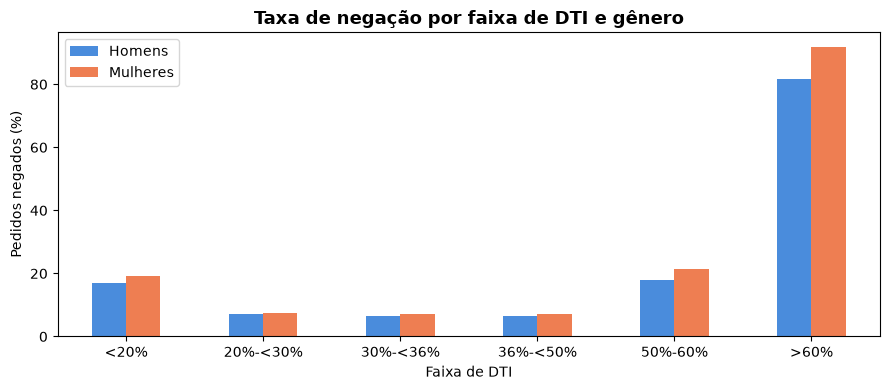

dti
<20%         2.10
20%-<30%     0.24
30%-<36%     0.54
36%-<50%     0.58
50%-60%      3.46
>60%        10.06
dtype: float64

In [11]:
por_dti = 100 * principal.groupby(["dti", "mulher"], observed=True)["negado"].mean().unstack()
por_dti.columns = ["Homens", "Mulheres"]

por_dti.plot(kind="bar", color=[AZUL, LARANJA], alpha=0.85, rot=0, figsize=(9, 4))
plt.ylabel("Pedidos negados (%)")
plt.xlabel("Faixa de DTI")
plt.title("Taxa de negação por faixa de DTI e gênero", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_negacao_dti.png", dpi=150)
plt.show()

(por_dti["Mulheres"] - por_dti["Homens"]).round(2)

Dentro das três faixas centrais de DTI, onde está a maior parte dos pedidos, a diferença entre mulheres e homens cai para algo entre 0,2 e 0,6 ponto percentual. Nas faixas extremas ela continua grande, chegando a 10 pontos acima de 60%. Olhar uma variável de cada vez não basta, e por isso a seção 6 controla todas ao mesmo tempo.

Por fim, a correlação entre as variáveis numéricas e o desfecho.

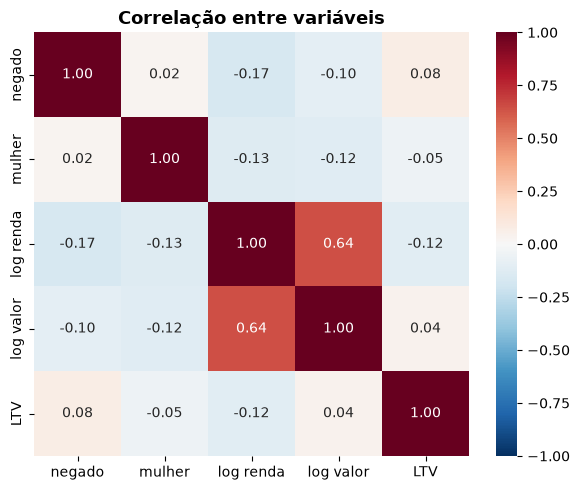

,negado,mulher,log renda,log valor,LTV
negado,1.00,0.02,-0.17,-0.10,0.08
mulher,0.02,1.00,-0.13,-0.12,-0.05
log renda,-0.17,-0.13,1.00,0.64,-0.12
log valor,-0.10,-0.12,0.64,1.00,0.04
LTV,0.08,-0.05,-0.12,0.04,1.00


In [12]:
numericas_corr = principal[["negado", "mulher", "income", "loan_amount", "combined_loan_to_value_ratio"]].copy()
numericas_corr["income"] = np.log(numericas_corr["income"].clip(lower=1))
numericas_corr["loan_amount"] = np.log(numericas_corr["loan_amount"])
numericas_corr["combined_loan_to_value_ratio"] = numericas_corr["combined_loan_to_value_ratio"].clip(0, 150)
numericas_corr.columns = ["negado", "mulher", "log renda", "log valor", "LTV"]
corr = numericas_corr.corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlação entre variáveis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

corr.round(2)

As correlações lineares são fracas. A negação tem correlação de -0,17 com o log da renda e de 0,08 com o LTV. Ser mulher tem correlação de -0,13 com a renda e de 0,02 com a negação. Renda e valor do empréstimo têm correlação de 0,64, já que quem ganha mais costuma pedir valores maiores. Correlação baixa não quer dizer ausência de relação, porque a relação com a negação pode não ser linear, como no caso do DTI acima.

## 5. Preparação para os modelos

Antes de ajustar os modelos, tratamos três pontos:

- renda zero ou negativa (erro de registro) impede o uso do logaritmo da renda, então essas linhas saem;
- o LTV tem valores impossíveis (até 29 milhões por cento). Para não perder essas linhas, limitamos o LTV aos percentis 0,1% e 99,9%;
- estado e idade faltantes saem, para que todas as análises usem a mesma amostra.

In [13]:
print("Renda <= 0:", (principal["income"] <= 0).sum())
modelos_df = principal[principal["income"] > 0].copy()

lim_inf, lim_sup = modelos_df["combined_loan_to_value_ratio"].quantile([0.001, 0.999])
print(f"LTV limitado ao intervalo [{lim_inf:.1f}, {lim_sup:.1f}]")
modelos_df["ltv"] = modelos_df["combined_loan_to_value_ratio"].clip(lim_inf, lim_sup)
modelos_df["log_renda"] = np.log(modelos_df["income"])
modelos_df["log_valor"] = np.log(modelos_df["loan_amount"])
modelos_df = modelos_df.dropna(subset=["state_code", "applicant_age"]).reset_index(drop=True)

print("Dimensão:", modelos_df.shape)

Renda <= 0: 7111
LTV limitado ao intervalo [14.0, 115.5]


Dimensão: (1532885, 18)


## 6. Regressão logística (H1)

Para separar o efeito do gênero do efeito do perfil de risco, usamos a regressão logística. O coeficiente de `mulher`, exponenciado, é a razão de chances (*odds ratio*, OR): OR = 1 indica a mesma chance de negação para os dois grupos, OR > 1 indica mais chance para as mulheres.

Ajustamos o modelo várias vezes, acrescentando controles aos poucos. Incluir efeitos fixos de estado e de banco equivale a colocar uma *dummy* para cada estado e para cada um dos cerca de 2.400 bancos. Com eles, o modelo compara homens e mulheres dentro do mesmo estado e do mesmo banco. Com tantas *dummies*, usamos a biblioteca `pyfixest`, que ajusta esse tipo de modelo sem criar as colunas explicitamente. Os erros-padrão são agrupados por banco, porque pedidos do mesmo banco não são independentes.

In [14]:
nomes_dti = {"<20%": "ate20", "20%-<30%": "20a30", "30%-<36%": "30a36", "36%-<50%": "36a50", "50%-60%": "50a60", ">60%": "acima60"}
nomes_raca = {"White": "branca", "Black or African American": "negra", "Asian": "asiatica",
              "American Indian or Alaska Native": "indigena", "Native Hawaiian or Other Pacific Islander": "pacifico",
              "2 or more minority races": "duas_mais", "Race Not Available": "nao_informada",
              "Free Form Text Only": "outra", "Joint": "outra"}
nomes_etnia = {"Not Hispanic or Latino": "nao_hispanica", "Hispanic or Latino": "hispanica",
               "Ethnicity Not Available": "nao_informada", "Joint": "outra", "Free Form Text Only": "outra"}

reg = modelos_df.copy()
reg["dti"] = pd.Categorical(reg["dti"].astype(str).map(nomes_dti), categories=list(nomes_dti.values()))
reg["tipo"] = pd.Categorical(reg["loan_type"], categories=["1", "2", "3", "4"])
reg["raca"] = pd.Categorical(reg["derived_race"].map(nomes_raca), categories=["branca", "negra", "asiatica", "indigena", "pacifico", "duas_mais", "nao_informada", "outra"])
reg["etnia"] = pd.Categorical(reg["derived_ethnicity"].map(nomes_etnia), categories=["nao_hispanica", "hispanica", "nao_informada", "outra"])
dummies = pd.get_dummies(reg[["dti", "tipo", "raca", "etnia"]], drop_first=True).astype(int)
reg = pd.concat([reg, dummies], axis=1)

controles = " + ".join(["log_renda", "ltv"] + [c for c in dummies.columns if c.startswith(("dti_", "tipo_"))])
raca = " + ".join(c for c in dummies.columns if c.startswith(("raca_", "etnia_")))

especificacoes = [
    ("(1) Só gênero", "negado ~ mulher"),
    ("(2) + renda, LTV, DTI e tipo", f"negado ~ mulher + {controles}"),
    ("(3) + efeito fixo de estado", f"negado ~ mulher + {controles} | state_code"),
    ("(4) + efeito fixo de banco [H1]", f"negado ~ mulher + {controles} | lei + state_code"),
    ("(5) = (4) + raça e etnia", f"negado ~ mulher + {controles} + {raca} | lei + state_code"),
]

linhas = []
for nome, formula in especificacoes:
    logit = pf.feglm(formula, data=reg, family="logit", vcov={"CRV1": "lei"})
    linear = pf.feols(formula, data=reg, vcov={"CRV1": "lei"})
    ic = logit.confint().loc["mulher"]
    linhas.append({"Especificação": nome, "N": logit._N, "OR": np.exp(logit.coef()["mulher"]),
                   "IC inf": np.exp(ic.iloc[0]), "IC sup": np.exp(ic.iloc[1]), "p": logit.pvalue()["mulher"],
                   "Efeito (p.p.)": 100 * linear.coef()["mulher"]})
    if nome.startswith("(4)"):
        modelo_h1 = logit

h1 = pd.DataFrame(linhas)
h1.round(3)

,Especificação,N,OR,IC inf,IC sup,p,Efeito (p.p.)
0,(1) Só gênero,1532885,1.160,1.098,1.225,0.000,1.409
1,"(2) + renda, LTV, DTI e tipo",1532885,1.022,0.988,1.057,0.205,0.197
2,(3) + efeito fixo de estado,1532885,1.010,0.976,1.045,0.561,0.123
3,(4) + efeito fixo de banco [H1],1514115,1.005,0.980,1.032,0.678,0.026
4,(5) = (4) + raça e etnia,1514115,0.963,0.942,0.985,0.001,-0.263


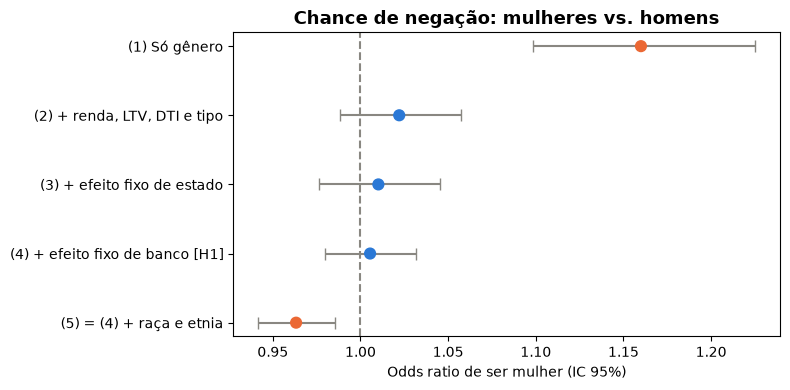

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(h1))[::-1]
ax.errorbar(h1["OR"], y, xerr=[h1["OR"] - h1["IC inf"], h1["IC sup"] - h1["OR"]], fmt="none", ecolor=CINZA, capsize=4)
ax.scatter(h1["OR"], y, color=[LARANJA if p < 0.05 else AZUL for p in h1["p"]], s=60, zorder=3)
ax.axvline(1, color=CINZA, linestyle="--")
ax.set_yticks(y)
ax.set_yticklabels(h1["Especificação"])
ax.set_xlabel("Odds ratio de ser mulher (IC 95%)")
ax.set_title("Chance de negação: mulheres vs. homens", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_h1.png", dpi=150)
plt.show()

Sem controles, a chance de negação das mulheres é 16% maior que a dos homens (OR = 1,16; IC 95% de 1,10 a 1,23), o que equivale a 1,4 ponto percentual. Quando entram renda, LTV, DTI e tipo de empréstimo, a OR cai para 1,02 e deixa de ser significativa (p = 0,21). Na especificação principal, com efeitos fixos de estado e de banco, a OR é 1,005 (IC 95% de 0,980 a 1,032; p = 0,68), um efeito de 0,03 ponto percentual. Não rejeitamos H0: comparando pessoas com o mesmo perfil, no mesmo estado e no mesmo banco, não encontramos diferença entre mulheres e homens.

Com raça e etnia no modelo, a OR fica em 0,963 (p = 0,001), e as mulheres passam a ter chance um pouco menor de negação. Entre as mulheres solicitantes, 16% são negras; entre os homens, 9%. Como solicitantes negros têm mais pedidos negados (notebook `08_robustez`), parte da diferença racial aparecia junto com o gênero quando a raça não estava no modelo.

Os coeficientes dos controles na especificação (4) mostram como cada fator se relaciona com a negação.

In [16]:
coefs = pd.DataFrame({"odds_ratio": np.exp(modelo_h1.coef()), "p": modelo_h1.pvalue()})
coefs.round(3)

,odds_ratio,p
Coefficient,,
mulher,1.005,0.678
log_renda,0.657,0.000
ltv,1.017,0.000
dti_20a30,0.508,0.000
dti_30a36,0.451,0.000
dti_36a50,0.477,0.000
dti_50a60,1.766,0.000
dti_acima60,48.169,0.000
tipo_2,0.859,0.052


Os controles se comportam como esperado. Um aumento de uma unidade no log da renda (renda cerca de 2,7 vezes maior) reduz a chance de negação em 34% (OR = 0,66). Cada ponto a mais de LTV aumenta a chance em 1,7%. DTI acima de 60% multiplica a chance por 48 em relação à faixa abaixo de 20%. O empréstimo VA tem chance de negação bem menor que o convencional (OR = 0,34).

As faixas de DTI entre 20% e 50% têm chance de negação menor que a faixa abaixo de 20%. Não investigamos o motivo desse resultado.

## 7. Modelos de classificação (H2)

Agora o problema é de classificação binária: prever se um pedido será negado (1) ou aprovado (0). Os atributos são log da renda, LTV, faixa de DTI, tipo de empréstimo, estado e faixa etária. Não usamos variáveis que só existem depois da decisão, como a taxa de juros ou o motivo da negação.

Separamos 70% para treino e 30% para teste, com estratificação pelo alvo e pelo gênero.

In [17]:
numericos = ["log_renda", "ltv"]
categoricos = ["dti", "loan_type", "state_code", "applicant_age"]
atributos = numericos + categoricos

clf = modelos_df[atributos + ["negado", "mulher"]].copy()
for c in categoricos:
    clf[c] = clf[c].astype(str).astype("category")

estrato = clf["negado"].astype(str) + clf["mulher"].astype(str)
treino, teste = train_test_split(clf, test_size=0.3, stratify=estrato, random_state=SEMENTE)
y_treino, y_teste = treino["negado"].values, teste["negado"].values

print("Treino:", treino.shape, f"- negados {y_treino.mean():.1%}")
print("Teste: ", teste.shape, f"- negados {y_teste.mean():.1%}")

Treino: (1073019, 8) - negados 10.5%
Teste:  (459866, 8) - negados 10.5%


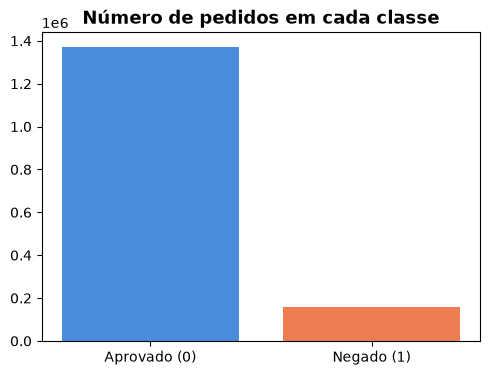

In [18]:
contagem = clf["negado"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
plt.bar(["Aprovado (0)", "Negado (1)"], contagem.values, color=[AZUL, LARANJA], alpha=0.85)
plt.title("Número de pedidos em cada classe", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

As classes são desbalanceadas: cerca de 9 aprovados para cada negado. Um modelo que aprovasse tudo acertaria perto de 90% dos casos sem servir para nada. Por isso a comparação usa a área sob a curva ROC (AUC) e a área sob a curva precisão-recall (PR-AUC), e não a acurácia.

### 7.1 Comparação de modelos

Comparamos os classificadores vistos na disciplina. Para cada um, escolhemos os hiperparâmetros com `GridSearchCV` (validação cruzada estratificada com 3 partes). Métodos como k-vizinhos e floresta aleatória ficam lentos com 1 milhão de linhas, então a comparação usa uma amostra de 50 mil pedidos do treino. As variáveis categóricas passam por *one-hot encoding* e as numéricas são padronizadas.

In [19]:
amostra = treino.sample(n=50_000, random_state=SEMENTE)
preparo = ColumnTransformer([
    ("num", StandardScaler(), numericos),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricos),
])

candidatos = {
    "Naive Bayes": (GaussianNB(), {}),
    "k-vizinhos": (KNeighborsClassifier(), {"modelo__n_neighbors": [25, 75, 150]}),
    "Árvore de decisão": (DecisionTreeClassifier(random_state=SEMENTE), {"modelo__max_depth": [5, 8, 12], "modelo__min_samples_leaf": [50, 200]}),
    "Regressão logística": (LogisticRegression(max_iter=2000), {"modelo__C": [0.1, 1, 10]}),
    "Floresta aleatória": (RandomForestClassifier(n_estimators=200, random_state=SEMENTE, n_jobs=-1), {"modelo__max_depth": [10, 20], "modelo__min_samples_leaf": [10, 50]}),
    "Gradient boosting": (HistGradientBoostingClassifier(max_iter=300, early_stopping=True, random_state=SEMENTE), {"modelo__learning_rate": [0.05, 0.1], "modelo__max_leaf_nodes": [15, 31]}),
}

comparacao = []
melhores = {}
for nome, (modelo, grade) in candidatos.items():
    busca = GridSearchCV(Pipeline([("preparo", preparo), ("modelo", modelo)]), grade,
                         scoring={"AUC": "roc_auc", "PR_AUC": "average_precision"}, refit="AUC",
                         cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE), n_jobs=-1)
    busca.fit(amostra[atributos], amostra["negado"])
    i = busca.best_index_
    melhores[nome] = busca.best_params_
    comparacao.append({"Modelo": nome, "AUC": busca.cv_results_["mean_test_AUC"][i],
                       "AUC dp": busca.cv_results_["std_test_AUC"][i],
                       "PR-AUC": busca.cv_results_["mean_test_PR_AUC"][i]})
    print(f"{nome}: AUC = {comparacao[-1]['AUC']:.4f}  {busca.best_params_}")

comparacao = pd.DataFrame(comparacao).sort_values("AUC", ascending=False)
comparacao.round(4)

Naive Bayes: AUC = 0.7018  {}


k-vizinhos: AUC = 0.7555  {'modelo__n_neighbors': 150}


Árvore de decisão: AUC = 0.7562  {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 200}


Regressão logística: AUC = 0.7464  {'modelo__C': 0.1}


Floresta aleatória: AUC = 0.7741  {'modelo__max_depth': 20, 'modelo__min_samples_leaf': 10}


Gradient boosting: AUC = 0.7754  {'modelo__learning_rate': 0.05, 'modelo__max_leaf_nodes': 31}


,Modelo,AUC,AUC dp,PR-AUC
5,Gradient boosting,0.7754,0.0013,0.5228
4,Floresta aleatória,0.7741,0.0018,0.5196
2,Árvore de decisão,0.7562,0.0034,0.4865
1,k-vizinhos,0.7555,0.0019,0.4690
3,Regressão logística,0.7464,0.0045,0.4771
0,Naive Bayes,0.7018,0.0061,0.3129


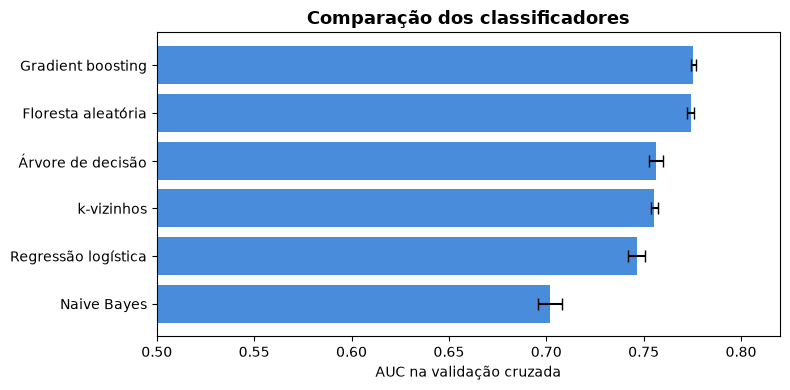

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(comparacao["Modelo"][::-1], comparacao["AUC"][::-1], xerr=comparacao["AUC dp"][::-1], color=AZUL, alpha=0.85, capsize=4)
ax.set_xlim(0.5, 0.82)
ax.set_xlabel("AUC na validação cruzada")
ax.set_title("Comparação dos classificadores", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_comparacao_modelos.png", dpi=150)
plt.show()

Os dois métodos de ensemble tiveram os melhores resultados: gradient boosting (AUC = 0,775) e floresta aleatória (0,774) estão praticamente empatados, dado o desvio-padrão entre as partes da validação cruzada. Depois vêm árvore de decisão e k-vizinhos (0,756), regressão logística (0,746) e Naive Bayes (0,702). Na PR-AUC a ordem é parecida. Para comparação, um classificador aleatório teria PR-AUC perto de 0,105, que é a proporção de negados.

Escolhemos o gradient boosting para a próxima etapa porque teve o melhor resultado e roda rápido na base inteira, com mais de 1 milhão de linhas.

### 7.2 Modelo final com e sem gênero

Treinamos o gradient boosting na base de treino inteira, com os hiperparâmetros escolhidos acima, em duas versões: com a variável `mulher` e sem ela. O `HistGradientBoostingClassifier` aceita as variáveis categóricas diretamente.

O modelo devolve uma probabilidade. Para transformá-la em decisão, escolhemos um limiar que faça o modelo negar a mesma proporção de pedidos que os bancos negaram no treino. Para não usar o teste nessa escolha, as probabilidades do treino vêm de validação cruzada.

In [21]:
params = {k.replace("modelo__", ""): v for k, v in melhores["Gradient boosting"].items()}
com_genero = ["mulher"] + atributos

modelos_finais, limiares, proba_cv = {}, {}, {}
for nome, colunas_x in [("Com gênero", com_genero), ("Sem gênero", atributos)]:
    gb = HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=300, early_stopping=True,
                                        random_state=SEMENTE, **params)
    proba_cv[nome] = cross_val_predict(gb, treino[colunas_x], y_treino, method="predict_proba",
                                       cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE))[:, 1]
    limiares[nome] = np.quantile(proba_cv[nome], 1 - y_treino.mean())
    modelos_finais[nome] = gb.fit(treino[colunas_x], y_treino)
    print(f"{nome}: limiar = {limiares[nome]:.4f}")

proba = {"Com gênero": modelos_finais["Com gênero"].predict_proba(teste[com_genero])[:, 1],
         "Sem gênero": modelos_finais["Sem gênero"].predict_proba(teste[atributos])[:, 1]}
decisao = {n: (proba[n] >= limiares[n]).astype(int) for n in proba}

pd.DataFrame({n: {"AUC": roc_auc_score(y_teste, p), "PR-AUC": average_precision_score(y_teste, p),
                  "Brier": brier_score_loss(y_teste, p), "Acurácia": accuracy_score(y_teste, decisao[n]),
                  "F1": f1_score(y_teste, decisao[n])} for n, p in proba.items()}).T.round(4)

Com gênero: limiar = 0.1443


Sem gênero: limiar = 0.1447


,AUC,PR-AUC,Brier,Acurácia,F1
Com gênero,0.7881,0.5486,0.0645,0.8936,0.4879
Sem gênero,0.7879,0.5487,0.0645,0.8939,0.4882


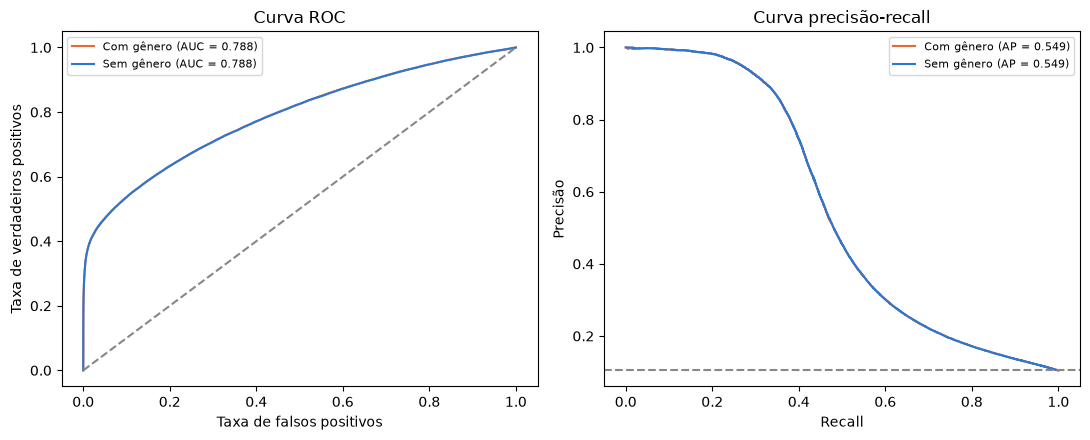

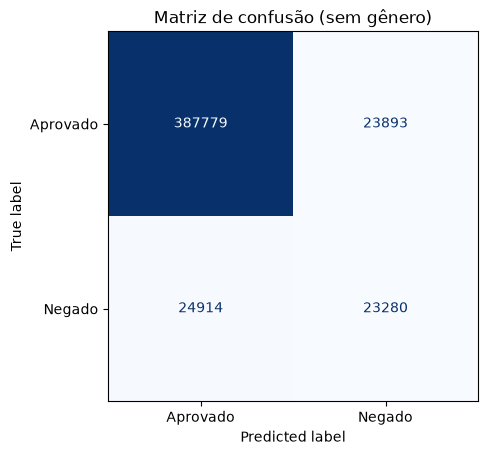

              precision    recall  f1-score   support

    Aprovado       0.94      0.94      0.94    411672
      Negado       0.49      0.48      0.49     48194

    accuracy                           0.89    459866
   macro avg       0.72      0.71      0.71    459866
weighted avg       0.89      0.89      0.89    459866



In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for (nome, p), cor in zip(proba.items(), [LARANJA, AZUL]):
    fpr, tpr, _ = roc_curve(y_teste, p)
    axes[0].plot(fpr, tpr, color=cor, label=f"{nome} (AUC = {roc_auc_score(y_teste, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_teste, p)
    axes[1].plot(rc, pr, color=cor, label=f"{nome} (AP = {average_precision_score(y_teste, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=CINZA, linestyle="--")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos")
axes[0].set_title("Curva ROC")
axes[1].axhline(y_teste.mean(), color=CINZA, linestyle="--")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].set_title("Curva precisão-recall")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figuras/projeto_final_roc_pr.png", dpi=150)
plt.show()

ConfusionMatrixDisplay(confusion_matrix(y_teste, decisao["Sem gênero"]), display_labels=["Aprovado", "Negado"]).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão (sem gênero)")
plt.show()
print(classification_report(y_teste, decisao["Sem gênero"], target_names=["Aprovado", "Negado"]))

No teste, os dois modelos têm o mesmo desempenho: AUC de 0,788 e PR-AUC de 0,549. Tirar a variável gênero não piora o modelo, ou seja, o gênero quase não traz informação nova para prever a decisão.

A acurácia de 89,4% parece alta, mas é praticamente a de um modelo que aprovasse todos os pedidos (89,5%). O modelo identifica 48% dos pedidos que os bancos negaram (recall), e, dos pedidos que ele nega, 49% foram de fato negados (precisão).

### 7.3 O mesmo pedido feito por um homem e por uma mulher

Com o modelo que recebe o gênero, avaliamos alguns perfis duas vezes, mudando só a variável `mulher`.

In [23]:
perfis = pd.DataFrame({
    "Perfil": ["Renda alta, pouca dívida", "Renda média", "Renda média, LTV alto", "Renda baixa, muita dívida"],
    "log_renda": np.log([150, 80, 80, 40]), "ltv": [70, 90, 100, 97],
    "dti": ["<20%", "30%-<36%", "36%-<50%", "50%-60%"], "loan_type": ["1", "1", "1", "2"],
    "state_code": ["CA", "TX", "TX", "FL"], "applicant_age": ["35-44", "35-44", "25-34", "25-34"],
})
for c in categoricos:
    perfis[c] = pd.Categorical(perfis[c], categories=treino[c].cat.categories)

simulacao = perfis[["Perfil"]].copy()
for nome, valor in [("Homem", 0), ("Mulher", 1)]:
    entrada = perfis.assign(mulher=valor)
    simulacao[f"{nome} (%)"] = 100 * modelos_finais["Com gênero"].predict_proba(entrada[com_genero])[:, 1]
simulacao["Diferença (p.p.)"] = simulacao["Mulher (%)"] - simulacao["Homem (%)"]
simulacao.round(2)

,Perfil,Homem (%),Mulher (%),Diferença (p.p.)
0,"Renda alta, pouca dívida",7.99,8.13,0.14
1,Renda média,8.22,7.85,-0.37
2,"Renda média, LTV alto",9.45,9.42,-0.04
3,"Renda baixa, muita dívida",27.19,27.86,0.67


Para um mesmo perfil, trocar homem por mulher muda a probabilidade de negação em menos de 0,7 ponto percentual, às vezes para cima e às vezes para baixo. Quando todo o resto é igual, o modelo praticamente não usa o gênero.

## 8. Equidade das decisões

Medimos a diferença entre os grupos de três formas, para as decisões reais dos bancos e para os dois modelos, no conjunto de teste:

- paridade demográfica (DP): taxa de negação das mulheres menos a dos homens, em pontos percentuais;
- *disparate impact* (DI): taxa de aprovação das mulheres dividida pela dos homens. Nos EUA, DI abaixo de 0,8 é tratado como indício de impacto adverso (regra dos 80%);
- DP condicional: a mesma diferença calculada dentro de cada combinação de faixa de DTI e quintil de LTV, e depois a média ponderada pelo tamanho de cada grupo.

Os intervalos de 95% vêm de 500 reamostragens *bootstrap* do teste.

In [24]:
mulher_t = teste["mulher"].values == 1
estrato_t = (teste["dti"].astype(str) + "|" + pd.qcut(teste["ltv"], 5, duplicates="drop").astype(str)).values
decisoes = {"Bancos (real)": y_teste, "Modelo com gênero": decisao["Com gênero"], "Modelo sem gênero": decisao["Sem gênero"]}

linhas = []
for nome, d in decisoes.items():
    tab = pd.DataFrame({"e": estrato_t, "m": mulher_t, "d": d}).groupby(["e", "m"])["d"].mean().unstack().dropna()
    pesos = pd.Series(estrato_t).value_counts()[tab.index]
    boot_dp = []
    for b in range(500):
        idx = np.random.randint(0, len(d), len(d))
        boot_dp.append(d[idx][mulher_t[idx]].mean() - d[idx][~mulher_t[idx]].mean())
    linhas.append({"Decisão": nome, "Homens (%)": 100 * d[~mulher_t].mean(), "Mulheres (%)": 100 * d[mulher_t].mean(),
                   "DP (p.p.)": 100 * (d[mulher_t].mean() - d[~mulher_t].mean()),
                   "DP IC inf": 100 * np.percentile(boot_dp, 2.5), "DP IC sup": 100 * np.percentile(boot_dp, 97.5),
                   "DI": (1 - d[mulher_t].mean()) / (1 - d[~mulher_t].mean()),
                   "DP condicional (p.p.)": 100 * np.average(tab[True] - tab[False], weights=pesos)})
equidade = pd.DataFrame(linhas).set_index("Decisão")
equidade.round(3)

,Homens (%),Mulheres (%),DP (p.p.),DP IC inf,DP IC sup,DI,DP condicional (p.p.)
Decisão,,,,,,,
Bancos (real),9.932,11.340,1.408,1.220,1.590,0.984,1.128
Modelo com gênero,9.025,12.275,3.250,3.062,3.446,0.964,3.276
Modelo sem gênero,8.844,12.477,3.633,3.454,3.828,0.960,3.645


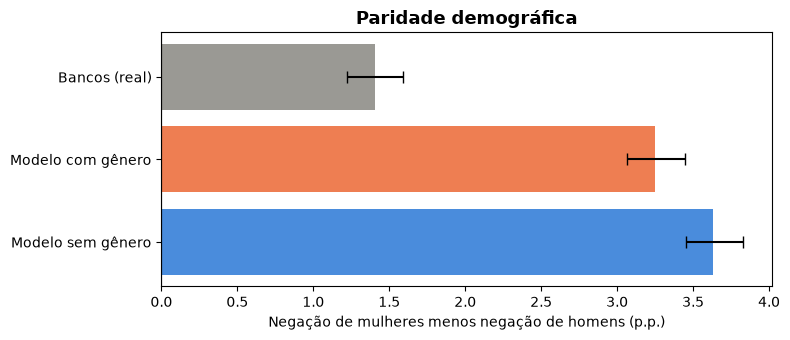

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(equidade))[::-1]
ax.barh(y, equidade["DP (p.p.)"], color=[CINZA, LARANJA, AZUL], alpha=0.85,
        xerr=[equidade["DP (p.p.)"] - equidade["DP IC inf"], equidade["DP IC sup"] - equidade["DP (p.p.)"]], capsize=4)
ax.set_yticks(y)
ax.set_yticklabels(equidade.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Negação de mulheres menos negação de homens (p.p.)")
ax.set_title("Paridade demográfica", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_equidade.png", dpi=150)
plt.show()

Nas decisões reais, as mulheres têm 1,41 ponto percentual a mais de negação (IC 95% de 1,22 a 1,59). Os dois modelos aumentam essa diferença: 3,25 pontos com gênero e 3,63 sem gênero, com intervalos que não se sobrepõem ao dos bancos. Retirar a variável gênero não reduziu a diferença, e o modelo sem gênero ficou um pouco mais desigual.

A diferença continua quando comparamos pedidos com DTI e LTV parecidos: 1,13 ponto nos bancos e 3,65 no modelo sem gênero. Com isso, a H2 se confirma.

Pela regra dos 80%, nenhum caso indica impacto adverso, porque todos os DI ficam acima de 0,96. Como a taxa de aprovação é alta para os dois grupos (entre 87% e 91%), uma diferença de 3,6 pontos na negação vira uma razão próxima de 1. As duas medidas respondem a perguntas diferentes, e por isso reportamos as duas.

O modelo passa por duas etapas: calcula uma probabilidade e depois aplica o limiar. Comparamos a diferença entre os grupos nas duas etapas.

Com gênero: diferença nas probabilidades = 1.51 p.p. | nas decisões = 3.25 p.p.
Sem gênero: diferença nas probabilidades = 1.71 p.p. | nas decisões = 3.63 p.p.


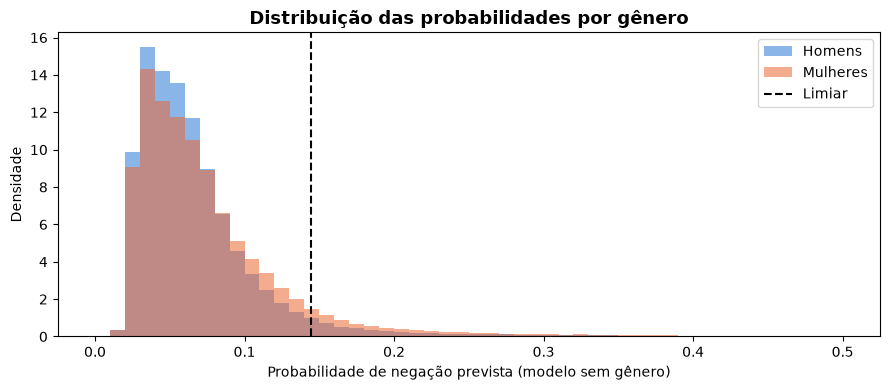

In [26]:
for nome in proba:
    dif_proba = 100 * (proba[nome][mulher_t].mean() - proba[nome][~mulher_t].mean())
    print(f"{nome}: diferença nas probabilidades = {dif_proba:.2f} p.p. | nas decisões = {equidade.loc['Modelo ' + nome.lower(), 'DP (p.p.)']:.2f} p.p.")

plt.figure(figsize=(9, 4))
bins = np.linspace(0, 0.5, 51)
plt.hist(proba["Sem gênero"][~mulher_t], bins=bins, density=True, alpha=0.55, color=AZUL, label="Homens")
plt.hist(proba["Sem gênero"][mulher_t], bins=bins, density=True, alpha=0.55, color=LARANJA, label="Mulheres")
plt.axvline(limiares["Sem gênero"], color="black", linestyle="--", label="Limiar")
plt.xlabel("Probabilidade de negação prevista (modelo sem gênero)")
plt.ylabel("Densidade")
plt.legend()
plt.title("Distribuição das probabilidades por gênero", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/projeto_final_probabilidades.png", dpi=150)
plt.show()

No modelo sem gênero, a diferença entre mulheres e homens é de 1,7 ponto percentual nas probabilidades, parecida com a dos bancos, e de 3,6 pontos depois do limiar. O histograma mostra o motivo: a maior parte dos pedidos fica abaixo do limiar (0,145), e a distribuição das mulheres tem a cauda direita um pouco mais pesada. Uma diferença pequena perto do limiar vira muitas decisões diferentes.

Métricas como *equalized odds* e calibração por grupo exigiriam saber quem pagou o empréstimo. Comparar os erros do modelo com a decisão do banco mostraria só o quanto o modelo imita os bancos, então essas métricas não foram calculadas.

## 9. Variáveis que carregam informação de gênero

Se o modelo sem gênero continua tratando os grupos de forma diferente, alguma variável está fazendo o papel do gênero. Para descobrir qual, treinamos um classificador que tenta prever o gênero a partir dos mesmos atributos. Se a AUC ficar acima de 0,5, os atributos carregam informação sobre o gênero.

Para calcular os valores SHAP, que mostram quanto cada variável pesou em cada previsão, convertemos as categorias em números inteiros, porque o `shap` não aceita as categorias em texto.

In [27]:
codigos = clf[atributos].copy()
codigos["dti"] = codigos["dti"].map({f: i for i, f in enumerate(ordem_dti)}).astype(int)
codigos["applicant_age"] = codigos["applicant_age"].map({f: i for i, f in enumerate(ordem_idade)}).astype(int)
codigos["loan_type"] = codigos["loan_type"].astype(int)
codigos["state_code"] = codigos["state_code"].cat.codes
X_tr, X_te = codigos.loc[treino.index], codigos.loc[teste.index]

modelo_genero = HistGradientBoostingClassifier(max_iter=300, early_stopping=True, random_state=SEMENTE, **params)
modelo_genero.fit(X_tr, treino["mulher"])
print(f"AUC para prever o gênero: {roc_auc_score(teste['mulher'], modelo_genero.predict_proba(X_te)[:, 1]):.4f}")

AUC para prever o gênero: 0.6646


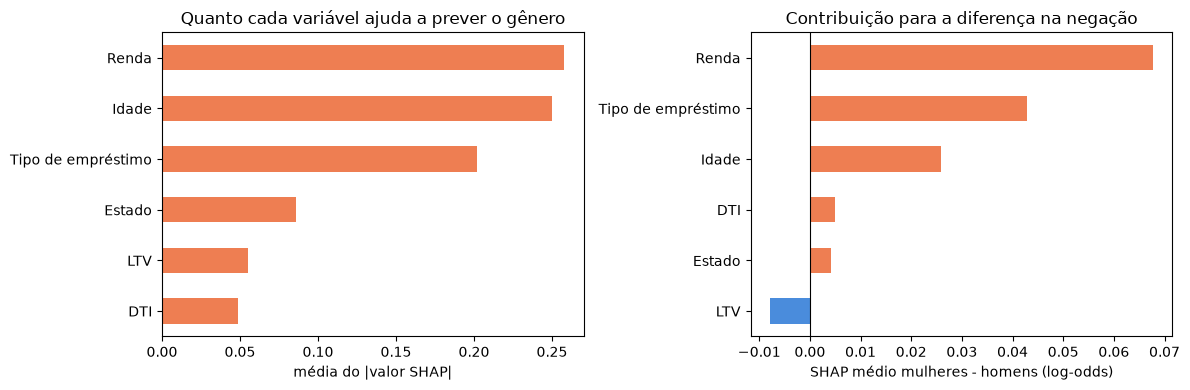

,Importância para prever o gênero,Parcela da diferença na negação (%)
Renda,0.257,49.247
Idade,0.250,18.785
Tipo de empréstimo,0.202,31.130
Estado,0.086,3.027
LTV,0.055,-5.756
DTI,0.049,3.566


In [28]:
nomes_var = {"log_renda": "Renda", "ltv": "LTV", "dti": "DTI", "loan_type": "Tipo de empréstimo",
             "state_code": "Estado", "applicant_age": "Idade"}
amostra_shap = X_te.sample(30_000, random_state=SEMENTE)
mulher_s = teste.loc[amostra_shap.index, "mulher"].values == 1

shap_genero = shap.TreeExplainer(modelo_genero)(amostra_shap)
importancia = pd.Series(np.abs(shap_genero.values).mean(0), index=atributos).rename(index=nomes_var)

modelo_credito = HistGradientBoostingClassifier(max_iter=300, early_stopping=True, random_state=SEMENTE, **params)
modelo_credito.fit(X_tr, y_treino)
shap_credito = shap.TreeExplainer(modelo_credito)(amostra_shap)
contribuicao = pd.Series(shap_credito.values[mulher_s].mean(0) - shap_credito.values[~mulher_s].mean(0),
                         index=atributos).rename(index=nomes_var)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
importancia.sort_values().plot(kind="barh", ax=axes[0], color=LARANJA, alpha=0.85)
axes[0].set_title("Quanto cada variável ajuda a prever o gênero")
axes[0].set_xlabel("média do |valor SHAP|")
contribuicao.sort_values().plot(kind="barh", ax=axes[1], color=[LARANJA if v > 0 else AZUL for v in contribuicao.sort_values()], alpha=0.85)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Contribuição para a diferença na negação")
axes[1].set_xlabel("SHAP médio mulheres - homens (log-odds)")
plt.tight_layout()
plt.savefig("figuras/projeto_final_proxies.png", dpi=150)
plt.show()

pd.DataFrame({"Importância para prever o gênero": importancia,
              "Parcela da diferença na negação (%)": 100 * contribuicao / contribuicao.sum()}).sort_values("Importância para prever o gênero", ascending=False).round(3)

In [29]:
comparar = pd.DataFrame({
    "Renda mediana (mil US$)": modelos_df.groupby("mulher")["income"].median(),
    "55 anos ou mais (%)": 100 * modelos_df.groupby("mulher")["applicant_age"].apply(lambda x: x.isin(["55-64", "65-74", ">74"]).mean()),
    "Empréstimo FHA (%)": 100 * modelos_df.groupby("mulher")["loan_type"].apply(lambda x: (x == "2").mean()),
    "Empréstimo VA (%)": 100 * modelos_df.groupby("mulher")["loan_type"].apply(lambda x: (x == "3").mean()),
}).T
comparar.columns = ["Homens", "Mulheres"]
comparar.round(1)

,Homens,Mulheres
Renda mediana (mil US$),95.0,82.0
55 anos ou mais (%),14.6,22.3
Empréstimo FHA (%),22.3,27.3
Empréstimo VA (%),12.7,4.5


Só com os atributos do modelo de crédito é possível prever o gênero com AUC de 0,665. É uma informação moderada, mas suficiente para o modelo diferenciar os grupos sem ver a variável `mulher`. As variáveis que mais ajudam a prever o gênero são renda, idade e tipo de empréstimo. Estado, LTV e DTI ajudam pouco.

Na diferença de negação prevista entre mulheres e homens, a renda responde por 49%, o tipo de empréstimo por 31% e a idade por 19%. O LTV puxa no sentido contrário (-6%), porque as mulheres financiam uma parte um pouco menor do imóvel.

O tipo de empréstimo é o caso mais fácil de entender. O VA tem chance de negação bem menor (OR = 0,34 na seção 6) e é usado por 12,7% dos homens e 4,5% das mulheres, porque é exclusivo para militares e veteranos. O modelo aprende que pedidos VA costumam ser aprovados, e isso favorece os homens mesmo sem a variável gênero.

## 10. Preço do crédito entre os aprovados (H3)

Entre os pedidos aprovados, olhamos três medidas de preço: a taxa de juros, o *rate spread* (diferença entre a taxa do empréstimo e uma taxa de referência do mercado, em pontos percentuais) e os custos totais de fechamento (em dólares). Usamos regressão linear com os mesmos controles e efeitos fixos da H1, mais o log do valor do empréstimo. Valores extremos são limitados aos percentis 0,1% e 99,9%.

In [30]:
aprovados = reg[reg["negado"] == 0].copy()
precos = {"interest_rate": "Taxa de juros (p.p.)", "rate_spread": "Rate spread (p.p.)", "total_loan_costs": "Custos totais (US$)"}

linhas = []
for coluna, nome in precos.items():
    base = aprovados.dropna(subset=[coluna]).copy()
    lo, hi = base[coluna].quantile([0.001, 0.999])
    base["y"] = base[coluna].clip(lo, hi)
    ajuste = pf.feols(f"y ~ mulher + {controles} + log_valor | lei + state_code", data=base, vcov={"CRV1": "lei"})
    ic = ajuste.confint().loc["mulher"]
    linhas.append({"Medida": nome, "N": ajuste._N, "Média": base["y"].mean(), "Diferença mulheres": ajuste.coef()["mulher"],
                   "IC inf": ic.iloc[0], "IC sup": ic.iloc[1], "p": ajuste.pvalue()["mulher"]})
h3 = pd.DataFrame(linhas)
h3.round(4)

,Medida,N,Média,Diferença mulheres,IC inf,IC sup,p
0,Taxa de juros (p.p.),1372113,6.3467,-0.0098,-0.0139,-0.0058,0.0
1,Rate spread (p.p.),1363457,0.1557,-0.0197,-0.0245,-0.0149,0.0
2,Custos totais (US$),1342148,7847.0880,68.8837,44.0698,93.6975,0.0


Entre os aprovados, as mulheres pagam taxa de juros 0,010 ponto percentual menor e rate spread 0,020 ponto menor, com intervalos que não incluem zero. Os custos de fechamento são 69 dólares maiores para elas (IC 95% de 44 a 94 dólares), cerca de 0,9% da média de 7.847 dólares.

Rejeitamos H0 para as três medidas, mas as diferenças são pequenas. Elas são significativas por causa do tamanho da amostra: 0,01 ponto na taxa de juros dá poucos dólares por mês num financiamento típico de 300 mil dólares.

## 11. Tentativa de reduzir a diferença

Na seção 8, vimos que o limiar único aumenta a diferença entre os grupos. Testamos duas alternativas para o modelo sem gênero, mudando só o limiar:

- limiar por grupo que reproduz a taxa de negação real de cada grupo no treino (o modelo passa a negar homens e mulheres na mesma proporção que os bancos);
- limiar por grupo que dá a mesma taxa de negação aos dois grupos (paridade demográfica).

Os limiares são escolhidos com as probabilidades de validação cruzada do treino, e as métricas são calculadas no teste. As duas alternativas usam o gênero no momento da decisão, o que tem implicações legais; o objetivo aqui é medir o custo de reduzir a diferença.

In [31]:
p_cv = proba_cv["Sem gênero"]
mulher_tr = treino["mulher"].values == 1
p_te = proba["Sem gênero"]

def limiar_por_taxa(p, taxa):
    return np.quantile(p, 1 - taxa)

cenarios = {
    "Limiar único": (limiares["Sem gênero"], limiares["Sem gênero"]),
    "Taxa real de cada grupo": (limiar_por_taxa(p_cv[~mulher_tr], y_treino[~mulher_tr].mean()),
                                limiar_por_taxa(p_cv[mulher_tr], y_treino[mulher_tr].mean())),
    "Mesma taxa para os dois": (limiar_por_taxa(p_cv[~mulher_tr], y_treino.mean()),
                                limiar_por_taxa(p_cv[mulher_tr], y_treino.mean())),
}

linhas = []
for nome, (lim_h, lim_m) in cenarios.items():
    d = np.where(mulher_t, p_te >= lim_m, p_te >= lim_h).astype(int)
    linhas.append({"Cenário": nome, "DP (p.p.)": 100 * (d[mulher_t].mean() - d[~mulher_t].mean()),
                   "Acurácia": accuracy_score(y_teste, d), "F1": f1_score(y_teste, d),
                   "Negados previstos (%)": 100 * d.mean()})
mitigacao = pd.DataFrame(linhas).set_index("Cenário")
mitigacao.round(4)

,DP (p.p.),Acurácia,F1,Negados previstos (%)
Cenário,,,,
Limiar único,3.6334,0.8939,0.4882,10.2580
Taxa real de cada grupo,1.4875,0.8940,0.4884,10.2395
Mesma taxa para os dois,0.0401,0.8939,0.4879,10.2380


Usar um limiar para cada grupo reduz a diferença sem custo visível no desempenho. Reproduzindo a taxa real de cada grupo, a diferença cai de 3,63 para 1,49 ponto percentual, perto da dos bancos. Igualando as taxas, ela vai para 0,04 ponto. A acurácia (89,4%) e o F1 (0,488) praticamente não mudam nos três cenários, e a proporção total de negados fica em torno de 10,2%.

Neste problema, a desigualdade extra do modelo vem quase toda da escolha do limiar. A ressalva é que o desempenho foi medido em relação à decisão dos bancos e não ao pagamento dos empréstimos, então não sabemos se os pedidos aprovados a mais seriam bons pagadores.

## 12. Conclusão

Analisamos cerca de 1,5 milhão de pedidos de financiamento para compra da casa própria nos EUA em 2025 para saber se mulheres têm mais crédito negado que homens.

Na comparação direta, as mulheres têm 12,1% dos pedidos negados e os homens 10,5%. Essa diferença some quando comparamos pessoas com a mesma renda, DTI, LTV e tipo de empréstimo, no mesmo estado e no mesmo banco (OR = 1,005; p = 0,68). Não encontramos evidência para H1: a diferença bruta vem do perfil dos solicitantes, principalmente da renda. Com raça e etnia no modelo, as mulheres têm chance um pouco menor de negação.

Na parte de aprendizado de máquina, comparamos seis classificadores, e o gradient boosting teve o melhor resultado (AUC = 0,788 no teste). Tirar a variável gênero não muda o desempenho e não deixa o modelo mais justo. O modelo nega 3,6 pontos percentuais a mais as mulheres, contra 1,4 ponto nas decisões reais, o que confirma H2. Renda, idade e tipo de empréstimo carregam informação sobre o gênero, e o limiar único aumenta a diferença. Com um limiar por grupo, a diferença cai sem perda de acurácia.

Na H3, as diferenças de preço são estatisticamente significativas, mas pequenas demais para ter efeito prático.

Limitações:

- o HMDA público não tem credit score, histórico de crédito, patrimônio nem informação de pagamento, e esses fatores podem mudar a comparação da H1;
- o gênero vem só como `Male` ou `Female`, e outras identidades não aparecem nos dados;
- os resultados são associações e não permitem conclusões causais;
- a amostra principal exclui pedidos com renda, DTI ou LTV faltantes, que são mais comuns entre os negados.

O trabalho pode ser ampliado com dados que incluam o credit score (a versão completa do HMDA, de acesso restrito), com a repetição da análise no HMDA 2024 para ver se o padrão se mantém, com a escolha de hiperparâmetros na base inteira e com outros métodos de redução de viés, como dar pesos diferentes aos exemplos de treino.